# Part 1: Preprocessing

Cell 1: setup, and count the photos

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q pillow-heif

import os, glob, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from pillow_heif import register_heif_opener
from scipy import ndimage
from skimage.filters import threshold_otsu
register_heif_opener()  # lets PIL open iPhone .HEIC photos

BASE = "/content/drive/MyDrive/COMP8240_PatchCore"
RAW = f"{BASE}/tealights_raw"
OUT = f"{BASE}/tealights_mvtec/tealight"   # MVTec layout: <category>/train, test, ground_truth
FOLDERS = {"train_good": "train/good", "test_good": "test/good", "used": "test/used", "empty": "test/empty"}
EXT = (".heic", ".jpg", ".jpeg", ".png")

files = {k: sorted(f for f in glob.glob(f"{RAW}/{k}/*") if f.lower().endswith(EXT)) for k in FOLDERS}
for k, v in files.items():
    print(f"{k}: {len(v)} photos, file types {sorted(set(os.path.splitext(f)[1].lower() for f in v))}")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 70.4 MB/s eta 0:00:00
train_good: 41 photos, file types ['.heic']
test_good: 18 photos, file types ['.heic']
used: 49 photos, file types ['.heic']
empty: 49 photos, file types ['.heic', '.jpg']


Cell 2: find the tealight in each photo, crop a square around it, and save in the MVTec layout

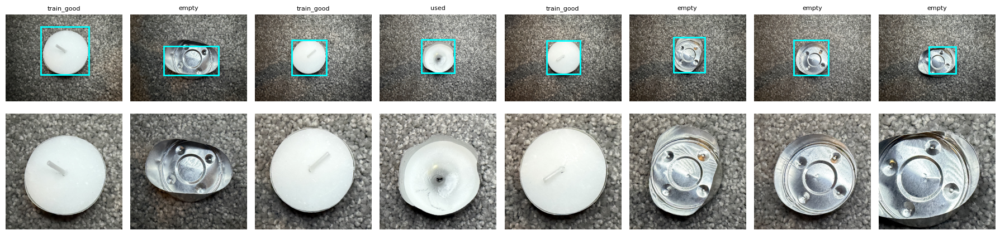

In [9]:
from skimage.feature import canny
from skimage.transform import hough_circle, hough_circle_peaks

def _small(img):
    g = img.convert("L")
    scale = 320 / max(g.size)
    g = g.resize((round(g.width * scale), round(g.height * scale)))
    return np.asarray(g, float), scale

def bright_box(g):
    h, w = g.shape
    # divide by a very blurred copy: removes the light-to-dark gradient across the carpet
    ratio = ndimage.gaussian_filter(g + 1, 3) / ndimage.gaussian_filter(g + 1, 0.2 * min(h, w))
    mask = ndimage.binary_fill_holes(ndimage.binary_closing(ratio > 1.25, iterations=3))
    mask = ndimage.binary_opening(mask, iterations=2)
    lab, _ = ndimage.label(mask)
    best, best_d = None, 1e9
    for i, sl in enumerate(ndimage.find_objects(lab), start=1):
        ys, xs = sl
        if (lab[sl] == i).sum() < 0.004 * h * w:
            continue
        if (ys.stop - ys.start) > 0.8 * h or (xs.stop - xs.start) > 0.8 * w:
            continue
        d = np.hypot((ys.start + ys.stop) / 2 - h / 2, (xs.start + xs.stop) / 2 - w / 2)
        if d < best_d:
            best, best_d = [xs.start, ys.start, xs.stop, ys.stop], d
    return best

def circle_box(g):
    h, w = g.shape
    # strongest edges only: the tealight outline is much sharper than the carpet speckle
    edges = canny(g / 255, sigma=3, low_threshold=0.85, high_threshold=0.95, use_quantiles=True)
    short = min(h, w)
    radii = np.arange(int(0.07 * short), int(0.42 * short), 2)
    score, cx, cy, r = hough_circle_peaks(hough_circle(edges, radii), radii, total_num_peaks=20)
    ok = [(s, x, y, rr) for s, x, y, rr in zip(score, cx, cy, r)
          if abs(x - w / 2) < 0.3 * w and abs(y - h / 2) < 0.3 * h]
    if not ok:
        return None
    # empty cups have an inner ring too: take the biggest circle that is almost as strong as the best
    best = max(o[0] for o in ok)
    _, x, y, rr = max((o for o in ok if o[0] >= 0.6 * best), key=lambda o: o[3])
    return [x - rr, y - rr, x + rr, y + rr]

def find_tealight(img):
    g, scale = _small(img)
    b, c = bright_box(g), circle_box(g)
    if b and c:
        ccx, ccy = (c[0] + c[2]) / 2, (c[1] + c[3]) / 2
        if b[0] <= ccx <= b[2] and b[1] <= ccy <= b[3]:  # same object: keep the union of both boxes
            b = [min(b[0], c[0]), min(b[1], c[1]), max(b[2], c[2]), max(b[3], c[3])]
    box = b or c
    return None if box is None else [v / scale for v in box]

def crop_square(img, box, margin=1.35, size=512):
    W, H = img.size
    if box is None:  # fallback if nothing was found: centre square
        s, cx, cy = min(W, H) * 0.5, W / 2, H / 2
    else:
        x0, y0, x1, y1 = box
        cx, cy, s = (x0 + x1) / 2, (y0 + y1) / 2, max(x1 - x0, y1 - y0) * margin
    s = min(s, W, H)
    # shift the window back inside the photo instead of adding black borders
    cx, cy = np.clip(cx, s / 2, W - s / 2), np.clip(cy, s / 2, H - s / 2)
    c = img.crop((round(cx - s / 2), round(cy - s / 2), round(cx + s / 2), round(cy + s / 2)))
    return c.resize((size, size), Image.LANCZOS)

# quick check on 8 photos: cyan box = what was found
import random
random.seed(1)
sample = random.sample([f for v in files.values() for f in v], 8)
fig, axes = plt.subplots(2, 8, figsize=(18, 4.5))
for c, f in enumerate(sample):
    img = ImageOps.exif_transpose(Image.open(f)).convert("RGB")
    box = find_tealight(img)
    axes[0, c].imshow(img)
    if box:
        x0, y0, x1, y1 = box
        axes[0, c].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="cyan", lw=2))
    axes[0, c].set_title(f.split("/")[-2], fontsize=8)
    axes[1, c].imshow(crop_square(img, box))
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [10]:
shutil.rmtree(f"{BASE}/tealights_mvtec", ignore_errors=True)
log = []
for k, sub in FOLDERS.items():
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)
    for i, f in enumerate(files[k]):
        img = ImageOps.exif_transpose(Image.open(f)).convert("RGB")  # fixes iPhone rotation
        box = find_tealight(img)
        name = f"{k}_{i:03d}.png"
        crop_square(img, box).save(f"{OUT}/{sub}/{name}")
        log.append({"folder": k, "source": os.path.basename(f), "saved_as": f"{sub}/{name}",
                    "found_automatically": box is not None, "original_size": img.size})

log = pd.DataFrame(log)
log.to_csv(f"{BASE}/tealights_mvtec/preprocessing_log.csv", index=False)
display(log.groupby("folder").agg(photos=("saved_as", "count"), found=("found_automatically", "sum")))

,photos,found
folder,,
empty,49,49
test_good,18,18
train_good,41,41
used,49,49


In [12]:
# these 3 were already cut off in the original photo (taken too close), so they're removed
REMOVE = ["empty_010", "empty_011", "empty_012"]
for name in REMOVE:
    os.remove(f"{OUT}/test/empty/{name}.png")
log["removed"] = log["saved_as"].str[-13:-4].isin(REMOVE)
log.to_csv(f"{BASE}/tealights_mvtec/preprocessing_log.csv", index=False)
print({k: len(os.listdir(f"{OUT}/{v}")) for k, v in FOLDERS.items()})

{'train_good': 41, 'test_good': 18, 'used': 49, 'empty': 46}


Cell 3: check every crop

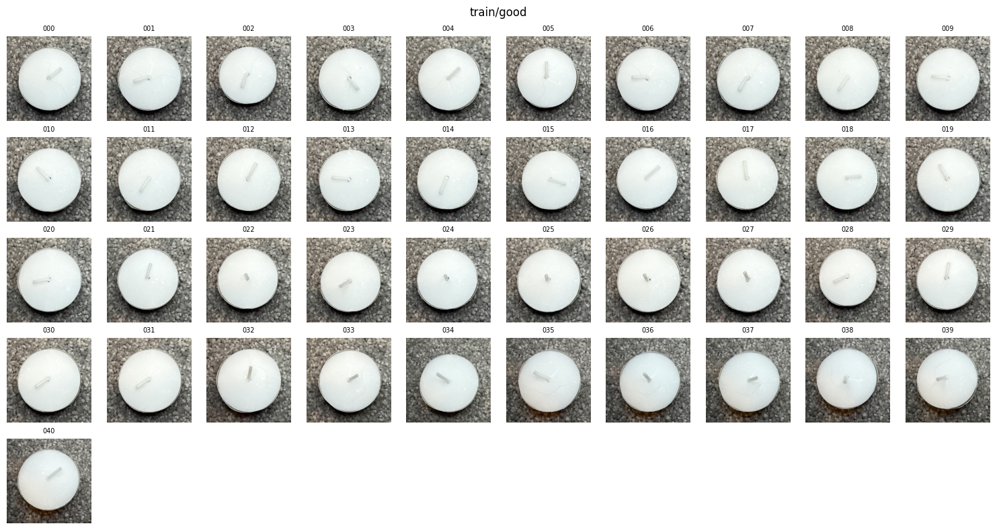

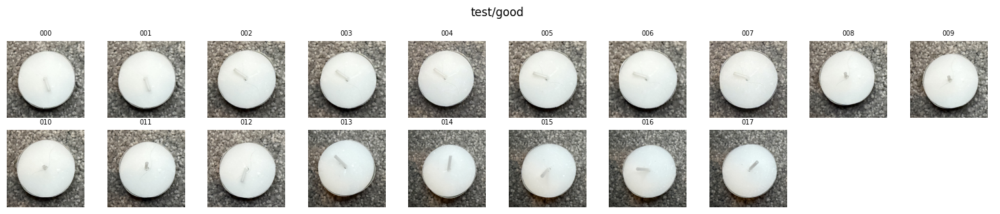

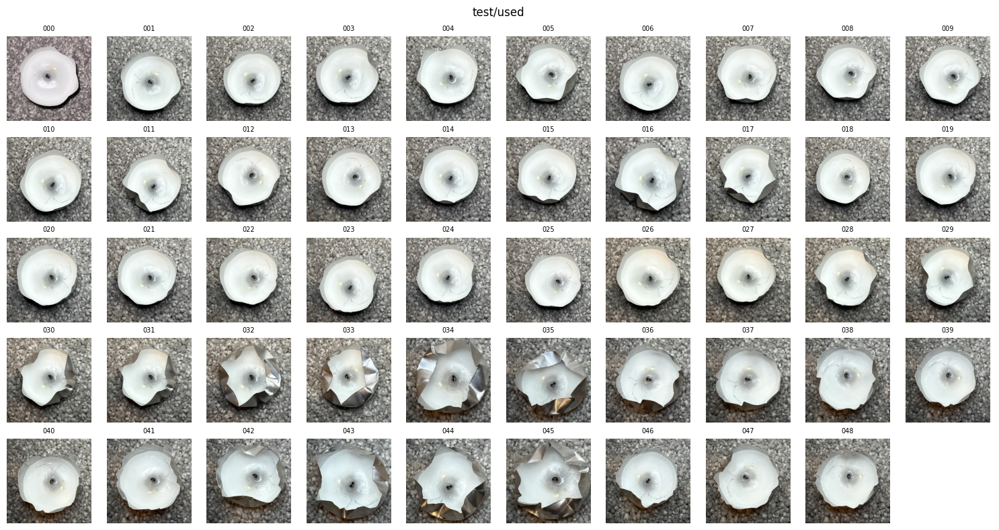

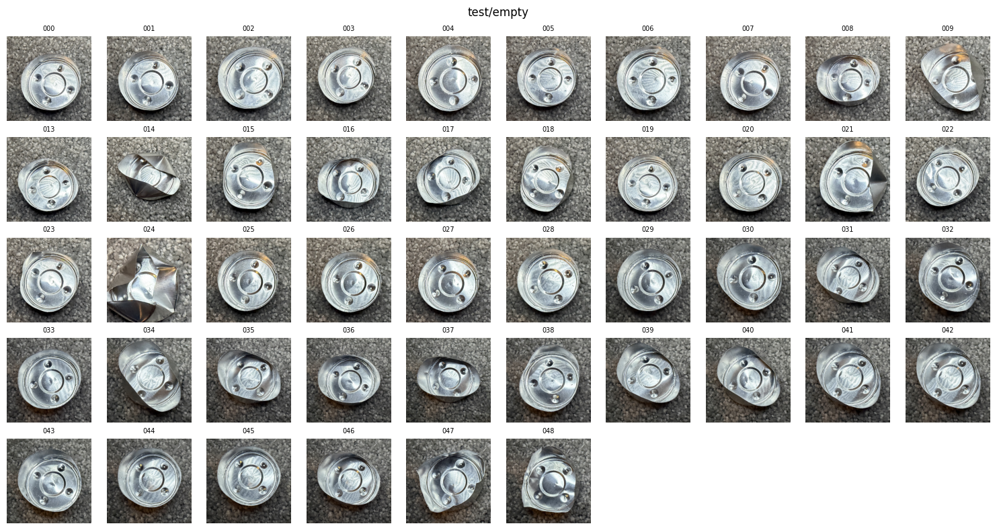

In [13]:
for sub in FOLDERS.values():
    fs = sorted(glob.glob(f"{OUT}/{sub}/*.png"))
    cols = 10
    rows = int(np.ceil(len(fs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 1.6 * rows))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, f in zip(np.atleast_1d(axes).flat, fs):
        ax.imshow(Image.open(f))
        ax.set_title(os.path.basename(f).split(".")[0][-3:], fontsize=7)
    fig.suptitle(sub, fontsize=12)
    plt.tight_layout(); plt.show()

Cell 4: figure

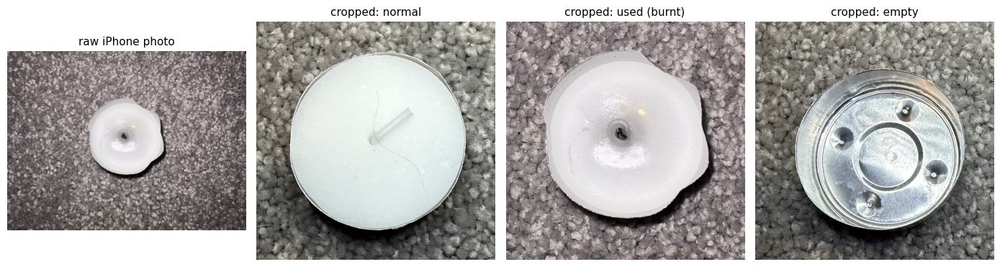

In [15]:
raw_ex = ImageOps.exif_transpose(Image.open(files["used"][0])).convert("RGB")
picks = [("train/good", "normal"), ("test/used", "used (burnt)"), ("test/empty", "empty")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(raw_ex); axes[0].set_title("raw iPhone photo", fontsize=11)
for ax, (sub, title) in zip(axes[1:], picks):
    ax.imshow(Image.open(sorted(glob.glob(f"{OUT}/{sub}/*.png"))[0]))
    ax.set_title(f"cropped: {title}", fontsize=11)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{BASE}/tealights_overview.png", dpi=150); plt.show()

# Part 2: Annotation

Cell 5: zip the defect images

In [16]:
tmp = "/content/to_annotate"
shutil.rmtree(tmp, ignore_errors=True); os.makedirs(tmp)
for d in ["used", "empty"]:
    for f in glob.glob(f"{OUT}/test/{d}/*.png"):
        shutil.copy(f, tmp)
shutil.make_archive(f"{BASE}/tealights_to_annotate", "zip", tmp)
print(len(os.listdir(tmp)), "images zipped to", f"{BASE}/tealights_to_annotate.zip")

95 images zipped to /content/drive/MyDrive/COMP8240_PatchCore/tealights_to_annotate.zip


Cell 6: turn the polygons into MVTec-style masks

In [18]:
coco = json.load(open(f"{BASE}/tealights_mvtec/annotations_coco.json"))
polys = {}
for a in coco["annotations"]:
    polys.setdefault(a["image_id"], []).extend(a["segmentation"])

empty_masks = []
for im in coco["images"]:
    name = os.path.splitext(os.path.basename(im["file_name"]))[0]
    defect = "used" if name.startswith("used") else "empty"
    m = Image.new("L", (im["width"], im["height"]), 0)
    draw = ImageDraw.Draw(m)
    for p in polys.get(im["id"], []):
        draw.polygon(list(zip(p[0::2], p[1::2])), fill=255)
    if not polys.get(im["id"]):
        empty_masks.append(name)
    os.makedirs(f"{OUT}/ground_truth/{defect}", exist_ok=True)
    # same name as the image + _mask, like MVTec, so sorted order matches
    m.resize((512, 512), Image.NEAREST).save(f"{OUT}/ground_truth/{defect}/{name}_mask.png")

for d in ["used", "empty"]:
    imgs = {os.path.basename(f)[:-4] for f in glob.glob(f"{OUT}/test/{d}/*.png")}
    masks = {os.path.basename(f)[:-9] for f in glob.glob(f"{OUT}/ground_truth/{d}/*_mask.png")}
    print(f"{d}: {len(imgs)} images, {len(masks)} masks, missing: {sorted(imgs - masks)}")
print("images with no polygon drawn:", empty_masks)

used 49 images, 49 placeholder masks
empty 46 images, 46 placeholder masks


Cell 7: check the masks are on the defects

In [ ]:
show = sorted(glob.glob(f"{OUT}/test/used/*.png"))[:3] + sorted(glob.glob(f"{OUT}/test/empty/*.png"))[:3]
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
for c, f in enumerate(show):
    d = f.split("/")[-2]
    m = Image.open(f"{OUT}/ground_truth/{d}/{os.path.basename(f)[:-4]}_mask.png")
    axes[0, c].imshow(Image.open(f)); axes[0, c].set_title(d, fontsize=10)
    axes[1, c].imshow(m, cmap="gray"); axes[1, c].set_title("mask", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{BASE}/tealights_annotation_examples.png", dpi=150); plt.show()